# Revision figures, multi-section arm (Comments 6, 10, 23, 25, 30)

New or revised figures for the revision of AIS 3400076. Everything is computed here from the repository models and data; the test set is the
original 85/10/5 split (global seed 42, as in `MULTI_helyx_training.ipynb`). Run `SINGLE/SINGLE_revision_figures.ipynb` first: Fig. 7 and Fig. S7
also use its `results/revision_single_test.npz`.

| Output (`results/`) | Figure |
|---|---|
| `fig7_per_point.pdf` | Fig. 7, error per reference point vs. normalized arc length, both arms (Comment 23) |
| `bending_error.pdf` | Fig. S7, tip error vs. bending angle, both arms (Comment 25) |
| `figS5_matched_ids.pdf`, `figS6_matched_ids.pdf` | Figs. S5 and S6 with target IDs and one color scale per quantity (SI comment 30) |
| `ik_ablation.json`, `ik_ablation.pdf` | Fig. S8b, data-driven secondary-objective ablation (Comment 6) |
| `fig3_network_map.pdf`, `fig4c_signal_flow.pdf` | Template for the Fig. 3 redraw and sketch of the Fig. 4c change (Comments 1, 10) |
| `revision_multi_test.npz` | per-sample test errors and bending angles |

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*torch.jit.load.*is deprecated")
import glob, json, os, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.spatial.transform import Rotation as R
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split

seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
COL = {"const": "tab:red", "affine": "tab:green", "quad": "tab:blue"}
LBL = {"const": "Constant", "affine": "Affine", "quad": "Quadratic"}


def original_split(n=10000):
    """Same split as the training notebooks: global seed 42, then train_test_split
    (0.15) and (1/3) without random_state, i.e. drawn from the seeded NumPy stream."""
    np.random.seed(42)
    idx = np.arange(n)
    tr, tmp = train_test_split(idx, test_size=0.15)
    va, te = train_test_split(tmp, test_size=1 / 3)
    return np.sort(tr), np.sort(va), np.sort(te)


def load_fields(shards, keys, indices, per=1000):
    """Loads only the requested global indices from the dataset shards (1000 samples each)."""
    indices = np.sort(np.asarray(indices))
    out = {k: [] for k in keys}
    for s, f in enumerate(shards):
        sel = indices[(indices >= s * per) & (indices < (s + 1) * per)] - s * per
        if len(sel) == 0:
            continue
        d = torch.load(f, map_location="cpu")
        for k in keys:
            out[k].extend([d[k][i] for i in sel])
        del d
    return {k: torch.stack(v) for k, v in out.items()}


def jit(path):
    m = torch.jit.load(path, map_location="cpu"); m.eval()
    return m


def run_model(model, x, batch=16):
    with torch.no_grad():
        return np.concatenate([model(x[i:i + batch].float()).numpy() for i in range(0, len(x), batch)])


def ang_dist_deg(a, b):
    return np.degrees(np.linalg.norm((R.from_euler("zyx", b) * R.from_euler("zyx", a).inv()).as_rotvec(), axis=-1))


def bending_from_euler(e):
    return np.degrees(np.arccos(np.clip(R.from_euler("zyx", e).as_matrix()[..., 2, 2], -1, 1)))


def section_curve(S, c0, c1, c2, phi, n=1000):
    """PPC section (dimensional arc length), same discretization as the testing notebooks."""
    v = np.linspace(0, S, n)
    th = c0 * v + 0.5 * c1 * v**2 + (1 / 3) * c2 * v**3
    pi = cumulative_trapezoid(np.sin(th), v, initial=0.0)
    t = np.array([np.cos(phi) * pi, np.sin(phi) * pi, cumulative_trapezoid(np.cos(th), v, initial=0.0)])
    cp, sp, ct, st = np.cos(phi), np.sin(phi), np.cos(th[-1]), np.sin(th[-1])
    Rend = np.array([[cp**2 * (ct - 1) + 1, cp * sp * (ct - 1), cp * st],
                     [sp * cp * (ct - 1), sp**2 * (ct - 1) + 1, sp * st],
                     [-cp * st, -sp * st, ct]])
    return t, Rend


FRACS = (1 / 3, 2 / 3, 1.0)


def points_chain(params, sections):
    """(S, c0, c1, c2, phi) per section -> reference points at 1/3, 2/3, 1 of each section, chained."""
    pts, Rcum, tcum = [], np.eye(3), np.zeros(3)
    for k in range(sections):
        t, Rend = section_curve(*params[5 * k:5 * k + 5])
        tg = Rcum @ t + tcum[:, None]
        pts += [tg[:, int(f * 999)] for f in FRACS]
        tcum, Rcum = tg[:, -1], Rcum @ Rend
    return np.array(pts)


def pad_params(arr, model, sections):
    """Labels/predictions -> (S, c0, c1, c2, phi) per section, zeros for missing coefficients."""
    w, out = {"quad": 5, "affine": 4, "const": 3}[model], []
    for k in range(sections):
        p = arr[w * k:w * k + w]
        out += list(p) if model == "quad" else ([p[0], p[1], p[2], 0.0, p[3]] if model == "affine" else [p[0], p[1], 0.0, 0.0, p[2]])
    return np.array(out, dtype=float)


def scatter_targets(fig, pos, t, err, vmax, cmap, title):
    """3D target map with target IDs (1-20) and a fixed color range."""
    a = fig.add_subplot(pos, projection="3d")
    sc = a.scatter(t[:, 0], t[:, 1], t[:, 2], c=err, cmap=cmap, vmin=0, vmax=vmax, s=18, depthshade=False)
    for i, p in enumerate(t[:, :3]):
        a.text(p[0], p[1], p[2], f" {i + 1}", fontsize=5.5)
    a.set_xlabel("X [mm]", fontsize=7, labelpad=-6); a.set_ylabel("Y [mm]", fontsize=7, labelpad=-6); a.set_zlabel("Z [mm]", fontsize=7, labelpad=-6)
    a.tick_params(labelsize=5, pad=-2); a.set_title(title, fontsize=8); a.view_init(elev=22, azim=-60)
    return sc


def load_ctrl(path):
    d = np.load(path); t, m = d["target"], d["mocap"]
    pe = np.linalg.norm(t[:, :3] - m[:, :3], axis=1)
    re_ = ang_dist_deg(t[:, 3:], m[:, 3:]) if t.shape[1] == 6 else None
    return t, pe, re_


## Test-set errors

Pose CNN $f_p^3$ (absolute tip errors, section bending from the relative orientation of consecutive tips) and curvature CNNs $f_C^3$
(3D error at the nine reference points between the chained backbones of predicted and labeled parameters).

In [2]:
SHARDS = sorted(glob.glob("data/MULTI_dataset/DatasetMulti*.pt"))
tr, va, te = original_split()
d = load_fields(SHARDS, ["X_images", "tip_1", "tip_2", "tip_3", "X_quad", "X_affine", "X_const"], te)
img = d["X_images"]
lab = np.concatenate([d["tip_1"].numpy(), d["tip_2"].numpy(), d["tip_3"].numpy()], axis=1)

pred = run_model(jit("models/vision/helyx_model.pt"), img, batch=8)
sec = {"I": 0, "II": 6, "III": 12}
prev = {"I": None, "II": 0, "III": 6}
abs_pos, abs_rot, bend = {}, {}, {}
for k, o in sec.items():
    abs_pos[k] = np.linalg.norm(pred[:, o:o + 3] - lab[:, o:o + 3], axis=1)
    abs_rot[k] = ang_dist_deg(pred[:, o + 3:o + 6], lab[:, o + 3:o + 6])
    p = prev[k]
    if p is None:
        bend[k] = bending_from_euler(lab[:, 3:6])
    else:
        Rloc = R.from_euler("zyx", lab[:, p + 3:p + 6]).inv() * R.from_euler("zyx", lab[:, o + 3:o + 6])
        bend[k] = np.degrees(np.arccos(np.clip(Rloc.as_matrix()[:, 2, 2], -1, 1)))

curv_files = {"const": "constant_model.pt", "affine": "affine_model.pt", "quad": "quadratic_model.pt"}
labels = {m: d[f"X_{m}"].numpy() for m in curv_files}
curv_err = {}
for m, fn in curv_files.items():
    cp = run_model(jit(f"models/curvature/{fn}"), img, batch=8)
    curv_err[m] = np.array([np.linalg.norm(points_chain(pad_params(cp[i], m, 3), 3) - points_chain(pad_params(labels[m][i], m, 3), 3), axis=1)
                            for i in range(len(te))])

np.savez_compressed("results/revision_multi_test.npz", te=te, **{f"abs_pos_{k}": v for k, v in abs_pos.items()},
                    **{f"abs_rot_{k}": v for k, v in abs_rot.items()}, **{f"bend_{k}": v for k, v in bend.items()},
                    **{f"{m}_vs_label": e for m, e in curv_err.items()})
for k in sec:
    q = lambda x: f"mean {x.mean():.2f} +/- {x.std():.2f}, median {np.median(x):.2f}, p95 {np.percentile(x, 95):.2f}, max {x.max():.2f}"
    print(f"Tip {k}: position {q(abs_pos[k])} mm; orientation {q(abs_rot[k])} deg")
for m, e in curv_err.items():
    print(f"{LBL[m]:9s} per point median {np.round(np.median(e, 0), 1)}, RMSE {np.round(np.sqrt((e**2).mean(0)), 1)} mm")

Tip I: position mean 4.44 +/- 2.68, median 3.92, p95 8.98, max 18.98 mm; orientation mean 6.78 +/- 15.94, median 4.77, p95 10.18, max 176.71 deg
Tip II: position mean 14.01 +/- 8.79, median 11.79, p95 29.83, max 66.00 mm; orientation mean 6.44 +/- 3.74, median 5.69, p95 13.31, max 28.21 deg
Tip III: position mean 26.44 +/- 16.49, median 22.60, p95 56.55, max 131.26 mm; orientation mean 8.74 +/- 13.05, median 6.94, p95 16.81, max 176.78 deg
Constant  per point median [ 0.8  2.6  5.8  9.6 14.4 20.2 26.9 34.2 41.5], RMSE [ 1.3  5.1 11.3 18.9 27.3 37.  48.  59.8 72.4] mm
Affine    per point median [ 0.7  2.5  5.4  9.1 13.7 19.7 26.2 32.8 40.8], RMSE [ 1.3  5.1 11.3 18.9 27.4 37.  47.8 59.4 71.7] mm
Quadratic per point median [ 0.7  2.5  5.6  9.5 14.2 20.3 26.1 33.3 40.7], RMSE [ 1.2  4.9 11.  18.2 25.9 34.9 45.2 56.2 68.1] mm


## Fig. 7: error per reference point vs. normalized arc length (Comment 23)

Markers: median over the 500 test samples; error bars: interquartile range. The bars of the current Fig. 7 are the sums of the per-point means.

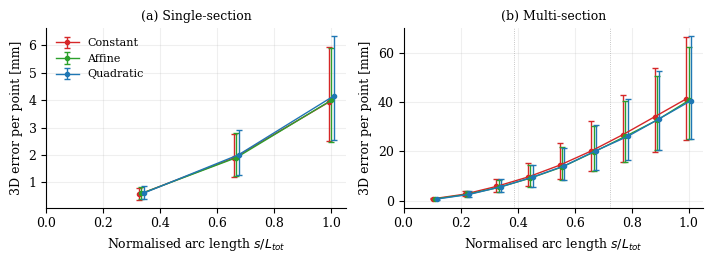

In [3]:
S = np.load("../SINGLE/results/revision_single_test.npz")
M = np.load("results/revision_multi_test.npz")
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.7))
for a, (D, n, title) in zip(ax, [(S, 3, "(a) Single-section"), (M, 9, "(b) Multi-section")]):
    x = np.arange(1, n + 1) / n
    for k, m in enumerate(["const", "affine", "quad"]):
        e = D[f"{m}_vs_label"]; med = np.median(e, 0)
        a.errorbar(x + (k - 1) * 0.008, med, yerr=[med - np.percentile(e, 25, 0), np.percentile(e, 75, 0) - med],
                   fmt="o-", ms=3, lw=1, capsize=2, color=COL[m], label=LBL[m])
    if n == 9:
        for b in (1 / 3, 2 / 3):
            a.axvline(b + 1 / 18, color="0.7", lw=0.6, ls=":")
    a.set_xlabel("Normalised arc length $s/L_{tot}$"); a.set_ylabel("3D error per point [mm]"); a.set_title(title, fontsize=9)
    a.set_xlim(0, 1.05); a.grid(alpha=0.2)
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("results/fig7_per_point.pdf"); plt.show()

## Fig. S7: tip position error vs. bending angle (Comment 25)

Black line: median in 5° bins; band: interquartile range. Multi-section samples with labeled bending above 60° (flipped motion-capture orientations, SI Section 6.1)
are outside the plotted range but included in $\rho$.

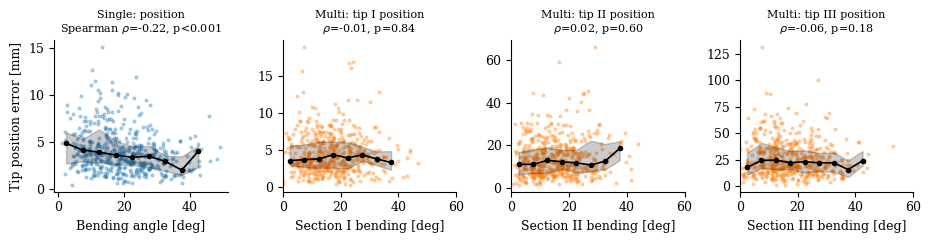

In [4]:
def binned(ax, x, y, edges, color):
    c = 0.5 * (edges[1:] + edges[:-1]); med, q1, q3 = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = y[(x >= lo) & (x < hi)]; ok = len(s) > 5
        med.append(np.median(s) if ok else np.nan); q1.append(np.percentile(s, 25) if ok else np.nan); q3.append(np.percentile(s, 75) if ok else np.nan)
    ax.plot(c, med, "-o", color=color, ms=3, lw=1.2); ax.fill_between(c, q1, q3, color=color, alpha=0.2)


fig, ax = plt.subplots(1, 4, figsize=(9.5, 2.5))
x, y = S["bend"], S["pos_err"]
ax[0].scatter(x, y, s=4, alpha=0.3, color="tab:blue"); binned(ax[0], x, y, np.arange(0, 55, 5), "k")
r, p = spearmanr(x, y); ax[0].set_title(f"Single: position\nSpearman $\\rho$={r:.2f}, p<0.001", fontsize=8)
ax[0].set_xlabel("Bending angle [deg]"); ax[0].set_ylabel("Tip position error [mm]")
for i, k in enumerate(["I", "II", "III"]):
    xb, yb = M[f"bend_{k}"], M[f"abs_pos_{k}"]; keep = xb <= 60
    ax[i + 1].scatter(xb[keep], yb[keep], s=4, alpha=0.3, color="tab:orange"); binned(ax[i + 1], xb, yb, np.arange(0, 65, 5), "k")
    r, p = spearmanr(xb, yb)
    ax[i + 1].set_title(f"Multi: tip {k} position\n$\\rho$={r:.2f}, p={p:.2f}", fontsize=8); ax[i + 1].set_xlabel(f"Section {k} bending [deg]"); ax[i + 1].set_xlim(0, 60)
plt.tight_layout(); plt.savefig("results/bending_error.pdf"); plt.show()

## Figs. S5 and S6 with target IDs and one color scale per quantity (SI comment 30)

Same data as the current Figs. S5 and S6. Numbers are the target IDs of Table S9.

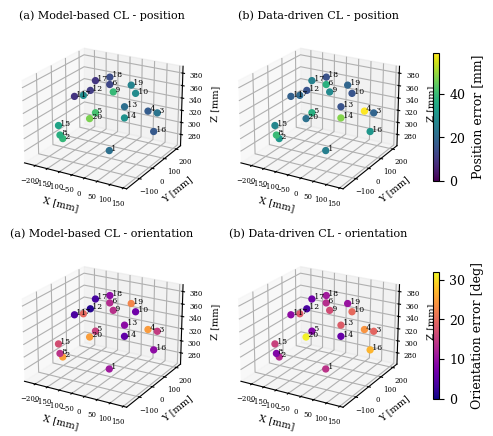

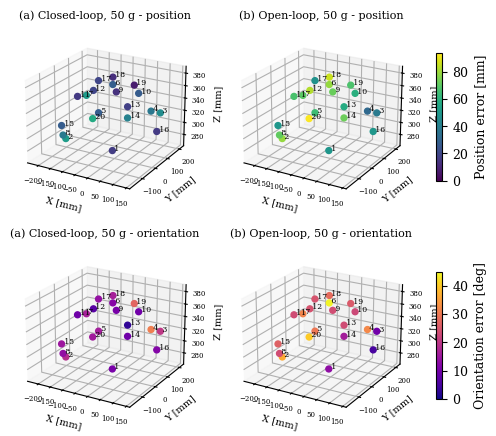

In [5]:
for name, pa, pb, la, lb in [("figS5", "ControlWorkspaceJacobian.npz", "ControlWorkspaceDatadriven.npz", "(a) Model-based CL", "(b) Data-driven CL"),
                             ("figS6", "ControlWorkspaceJacobian_W50g.npz", "ControlWorkspaceOpenLoopJacobian_W50g.npz", "(a) Closed-loop, 50 g", "(b) Open-loop, 50 g")]:
    tA, pA, rA = load_ctrl(f"results/{pa}"); tB, pB, rB = load_ctrl(f"results/{pb}")
    vp, vr = np.ceil(max(pA.max(), pB.max())), np.ceil(max(rA.max(), rB.max()))
    fig = plt.figure(figsize=(6.4, 5.2))
    scatter_targets(fig, 221, tA, pA, vp, "viridis", la + " - position"); s1 = scatter_targets(fig, 222, tB, pB, vp, "viridis", lb + " - position")
    scatter_targets(fig, 223, tA, rA, vr, "plasma", la + " - orientation"); s2 = scatter_targets(fig, 224, tB, rB, vr, "plasma", lb + " - orientation")
    fig.colorbar(s1, ax=fig.axes[:2], shrink=0.7, label="Position error [mm]"); fig.colorbar(s2, ax=fig.axes[2:4], shrink=0.7, label="Orientation error [deg]")
    plt.savefig(f"results/{name}_matched_ids.pdf"); plt.show()

## Fig. S8b: data-driven secondary-objective ablation (Comment 6)

$N_l^3$ is trained twice with the loss of Eq. 11 through the frozen forward network `models/kinematics/FK_model.pt`: $\zeta = 0.01$ (paper) and $\zeta = 0$,
with the same data, split and seed. Both are evaluated through $N_p^3$ on 500 held-out poses and on the 20 control targets: position/orientation error
of $N_p^3(N_l^3(p))$, $H(l) = \frac{1}{2}\|l - \bar l\|^2$ and RMS deviation of $l$ from $\bar l$. This is an offline (simulated) comparison; training takes about 20 minutes on CPU.
Check: the deployed `IK_model.pt` gives the same $H(l)$ on the held-out poses as the $\zeta = 0.01$ retrain.

In [6]:
import torch.nn as nn

fk = jit("models/kinematics/FK_model.pt")
for prm in fk.parameters():
    prm.requires_grad_(False)
dfk = torch.load("data/FKdata.pt", map_location="cpu")
L = torch.stack(list(dfk["DELTAL"])).float(); P = torch.stack(list(dfk["tip3_pose"])).float()
idx = np.arange(len(L))
tr_k, tmp_k = train_test_split(idx, test_size=0.15, random_state=42); va_k, te_k = train_test_split(tmp_k, test_size=1 / 3, random_state=42)
pm, ps = P[tr_k].mean(0), P[tr_k].std(0); lm, ls = L[tr_k].mean(0), L[tr_k].std(0)
lbar = torch.load("models/kinematics/DELTAL_stats.pt")["mean"].float()
targets = torch.tensor(np.load("results/ControlWorkspace.npz")["pose"], dtype=torch.float32)


def ik_net():
    return nn.Sequential(nn.Linear(6, 128), nn.ELU(), nn.Linear(128, 128), nn.ELU(), nn.Linear(128, 128), nn.ELU(),
                         nn.Linear(128, 128), nn.ELU(), nn.Linear(128, 9))


def ik_loss(model, pn, zeta):
    ln = model(pn)
    return nn.functional.huber_loss((fk(ln * ls + lm) - pm) / ps, pn, delta=1.0) + zeta * torch.mean(ln ** 2)


def train_ik(zeta, epochs=1500, patience=50):
    torch.manual_seed(42)
    m = ik_net(); opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=5e-6)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.9, patience=15)
    Xtr, Xva = (P[tr_k] - pm) / ps, (P[va_k] - pm) / ps
    best, state, c = 1e9, None, 0
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; opt.zero_grad(); loss = ik_loss(m, Xtr[b], zeta); loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        m.eval()
        with torch.no_grad():
            v = ik_loss(m, Xva, zeta).item()
        sch.step(v)
        if v < best - 1e-6:
            best, state, c = v, {k: t.clone() for k, t in m.state_dict().items()}, 0
        else:
            c += 1
            if c > patience:
                break
    m.load_state_dict(state); m.eval()
    return m, ep


def evaluate_ik(fn, poses):
    with torch.no_grad():
        l = fn(poses); pr = fk(l)
    pos = torch.linalg.norm(pr[:, :3] - poses[:, :3], dim=1).numpy(); rot = ang_dist_deg(pr[:, 3:].numpy(), poses[:, 3:].numpy())
    H = 0.5 * ((l - lbar) ** 2).sum(1).numpy(); rms = torch.sqrt(((l - lbar) ** 2).mean(1)).numpy()
    return {"pos_mean": pos.mean(), "pos_std": pos.std(), "rot_mean": rot.mean(), "rot_std": rot.std(),
            "H_mean": H.mean(), "H_std": H.std(), "rms_dev_mean": rms.mean(), "rms_dev_std": rms.std()}


ik_res = {}
for z in (0.01, 0.0):
    model, ep = train_ik(z)
    fn = lambda poses, model=model: model((poses - pm) / ps) * ls + lm
    ik_res[f"zeta={z}"] = {"epochs": ep, "test": evaluate_ik(fn, P[te_k]), "control_targets": evaluate_ik(fn, targets)}
ik_res["deployed_IK_model"] = {"test": evaluate_ik(jit("models/kinematics/IK_model.pt"), P[te_k]),
                               "control_targets": evaluate_ik(jit("models/kinematics/IK_model.pt"), targets)}
json.dump(ik_res, open("results/ik_ablation.json", "w"), indent=1, default=float)
for k, v in ik_res.items():
    print(k, {s: {a: round(float(b), 2) for a, b in r.items()} for s, r in v.items() if s != "epochs"})

zeta=0.01 {'test': {'pos_mean': 5.91, 'pos_std': 3.45, 'rot_mean': 1.66, 'rot_std': 1.1, 'H_mean': 326.0, 'H_std': 194.92, 'rms_dev_mean': 8.15, 'rms_dev_std': 2.46}, 'control_targets': {'pos_mean': 5.09, 'pos_std': 2.15, 'rot_mean': 2.41, 'rot_std': 1.36, 'H_mean': 370.53, 'H_std': 165.51, 'rms_dev_mean': 8.84, 'rms_dev_std': 2.07}}
zeta=0.0 {'test': {'pos_mean': 3.21, 'pos_std': 2.67, 'rot_mean': 1.19, 'rot_std': 0.78, 'H_mean': 450.71, 'H_std': 290.67, 'rms_dev_mean': 9.54, 'rms_dev_std': 3.04}, 'control_targets': {'pos_mean': 4.62, 'pos_std': 2.34, 'rot_mean': 1.82, 'rot_std': 1.33, 'H_mean': 487.48, 'H_std': 257.23, 'rms_dev_mean': 10.07, 'rms_dev_std': 2.61}}
deployed_IK_model {'test': {'pos_mean': 6.65, 'pos_std': 3.71, 'rot_mean': 2.61, 'rot_std': 1.59, 'H_mean': 326.03, 'H_std': 189.13, 'rms_dev_mean': 8.16, 'rms_dev_std': 2.41}, 'control_targets': {'pos_mean': 4.31, 'pos_std': 2.14, 'rot_mean': 3.3, 'rot_std': 1.6, 'H_mean': 355.3, 'H_std': 156.33, 'rms_dev_mean': 8.65, 'rms_

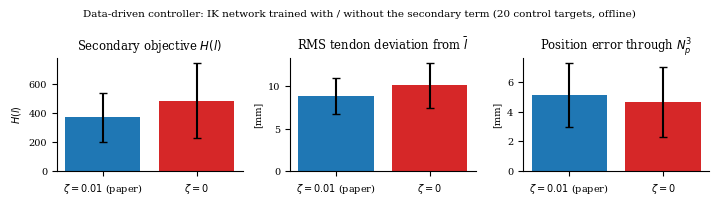

In [7]:
a, b = ik_res["zeta=0.01"]["control_targets"], ik_res["zeta=0.0"]["control_targets"]
plt.rcParams.update({"font.size": 7})
fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.0))
for k, (mk, sk, title, yl) in enumerate([("H_mean", "H_std", "Secondary objective $H(l)$", "$H(l)$"),
                                         ("rms_dev_mean", "rms_dev_std", "RMS tendon deviation from $\\bar l$", "[mm]"),
                                         ("pos_mean", "pos_std", "Position error through $N_p^3$", "[mm]")]):
    ax[k].bar([0, 1], [a[mk], b[mk]], yerr=[a[sk], b[sk]], capsize=3, color=["tab:blue", "tab:red"])
    ax[k].set_xticks([0, 1], ["$\\zeta=0.01$ (paper)", "$\\zeta=0$"]); ax[k].set_title(title); ax[k].set_ylabel(yl)
fig.suptitle("Data-driven controller: IK network trained with / without the secondary term (20 control targets, offline)", fontsize=7.5)
plt.tight_layout(); plt.savefig("results/ik_ablation.pdf"); plt.show()
plt.rcParams.update({"font.size": 9})

## Diagrams for Fig. 3 and Fig. 4c (Comments 1, 10)

`fig3_network_map.pdf`: every network with its inputs, outputs and sizes, as implemented in the training notebooks (template for the Fig. 3 redraw).
`fig4c_signal_flow.pdf`: Fig. 4c with the encoder path (model-based only) and the curvature CNN outside the loop. Requires Graphviz (`dot`).

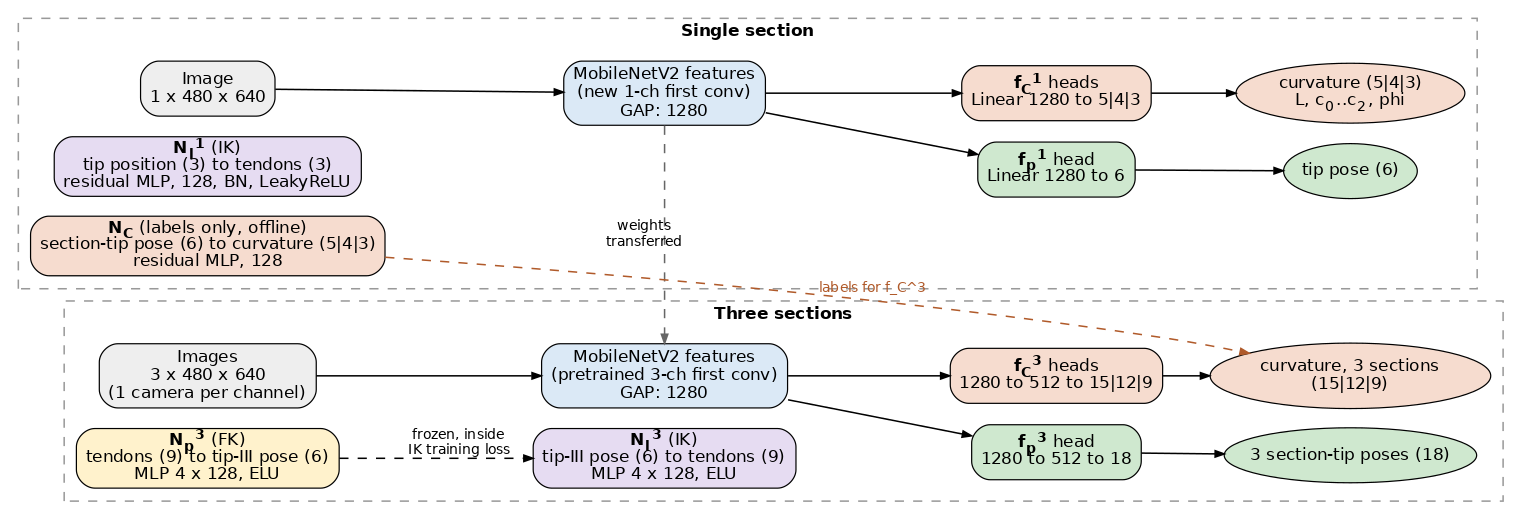

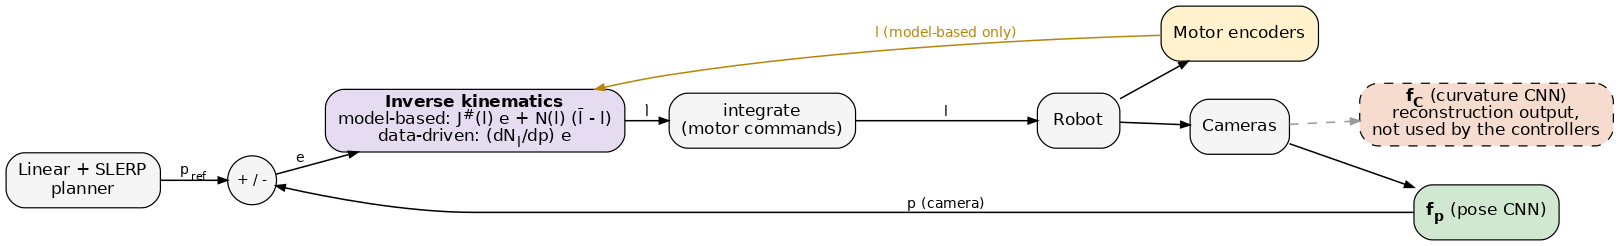

In [8]:
import subprocess
from IPython.display import Image, display

net = r"""digraph G {
rankdir=LR; nodesep=0.18; ranksep=0.4; newrank=true;
node [shape=box, style="rounded,filled", fontname="Helvetica", fontsize=11, penwidth=0.8, margin="0.08,0.04"];
edge [fontname="Helvetica", fontsize=9, arrowsize=0.6];
subgraph cluster_s { label=<<B>Single section</B>>; fontname="Helvetica"; fontsize=11; style=dashed; color="#999999";
 img1 [label=<Image<BR/>1 x 480 x 640>, fillcolor="#eeeeee"];
 bb1 [label=<MobileNetV2 features<BR/>(new 1-ch first conv)<BR/>GAP: 1280>, fillcolor="#dbe9f6"];
 fp1 [label=<<B>f<SUB>p</SUB><SUP>1</SUP></B> head<BR/>Linear 1280 to 6>, fillcolor="#cfe8cf"];
 fc1 [label=<<B>f<SUB>C</SUB><SUP>1</SUP></B> heads<BR/>Linear 1280 to 5|4|3>, fillcolor="#f6dccf"];
 p1 [label=<tip pose (6)>, shape=ellipse, fillcolor="#cfe8cf"];
 c1 [label=<curvature (5|4|3)<BR/>L, c<SUB>0</SUB>..c<SUB>2</SUB>, phi>, shape=ellipse, fillcolor="#f6dccf"];
 img1 -> bb1; bb1 -> fp1 -> p1; bb1 -> fc1 -> c1;
 nl1 [label=<<B>N<SUB>l</SUB><SUP>1</SUP></B> (IK)<BR/>tip position (3) to tendons (3)<BR/>residual MLP, 128, BN, LeakyReLU>, fillcolor="#e6dcf2"];
 nc [label=<<B>N<SUB>C</SUB></B> (labels only, offline)<BR/>section-tip pose (6) to curvature (5|4|3)<BR/>residual MLP, 128>, fillcolor="#f6dccf"];
}
subgraph cluster_m { label=<<B>Three sections</B>>; fontname="Helvetica"; fontsize=11; style=dashed; color="#999999";
 img3 [label=<Images<BR/>3 x 480 x 640<BR/>(1 camera per channel)>, fillcolor="#eeeeee"];
 bb3 [label=<MobileNetV2 features<BR/>(pretrained 3-ch first conv)<BR/>GAP: 1280>, fillcolor="#dbe9f6"];
 fp3 [label=<<B>f<SUB>p</SUB><SUP>3</SUP></B> head<BR/>1280 to 512 to 18>, fillcolor="#cfe8cf"];
 fc3 [label=<<B>f<SUB>C</SUB><SUP>3</SUP></B> heads<BR/>1280 to 512 to 15|12|9>, fillcolor="#f6dccf"];
 p3 [label=<3 section-tip poses (18)>, shape=ellipse, fillcolor="#cfe8cf"];
 c3 [label=<curvature, 3 sections<BR/>(15|12|9)>, shape=ellipse, fillcolor="#f6dccf"];
 img3 -> bb3; bb3 -> fp3 -> p3; bb3 -> fc3 -> c3;
 np3 [label=<<B>N<SUB>p</SUB><SUP>3</SUP></B> (FK)<BR/>tendons (9) to tip-III pose (6)<BR/>MLP 4 x 128, ELU>, fillcolor="#fff2cc"];
 nl3 [label=<<B>N<SUB>l</SUB><SUP>3</SUP></B> (IK)<BR/>tip-III pose (6) to tendons (9)<BR/>MLP 4 x 128, ELU>, fillcolor="#e6dcf2"];
 np3 -> nl3 [label="frozen, inside\nIK training loss", style=dashed];
}
bb1 -> bb3 [style=dashed, label="weights\ntransferred", color="#666666", constraint=false];
nc -> c3 [style=dashed, label="labels for f_C^3", color="#b05a2a", fontcolor="#b05a2a", constraint=false];
{rank=same; img1; nl1;} {rank=same; img3; np3;}
}"""

ctrl = r"""digraph G {
rankdir=LR; nodesep=0.35; ranksep=0.35;
node [shape=box, style="rounded,filled", fillcolor="#f5f5f5", fontname="Helvetica", fontsize=11, penwidth=0.8];
edge [fontname="Helvetica", fontsize=9, arrowsize=0.6];
plan [label=<Linear + SLERP<BR/>planner>]; sum [label="+ / -", shape=circle, width=0.45, fixedsize=true, fontsize=9];
ik [label=<<B>Inverse kinematics</B><BR/>model-based: J<SUP>#</SUP>(l) e + N(l) (l&#772; - l)<BR/>data-driven: (dN<SUB>l</SUB>/dp) e>, fillcolor="#e6dcf2"];
int [label=<integrate<BR/>(motor commands)>]; rob [label=<Robot>];
cam [label=<Cameras>]; pose [label=<<B>f<SUB>p</SUB></B> (pose CNN)>, fillcolor="#cfe8cf"];
enc [label=<Motor encoders>, fillcolor="#fff2cc"];
curv [label=<<B>f<SUB>C</SUB></B> (curvature CNN)<BR/>reconstruction output,<BR/>not used by the controllers>, fillcolor="#f6dccf", style="rounded,filled,dashed"];
plan -> sum [label=<p<SUB>ref</SUB>>]; sum -> ik [label="e"]; ik -> int [label=<l&#775;>]; int -> rob [label="l"]; rob -> cam;
cam -> pose; pose -> sum [label="p (camera)"];
rob -> enc; enc -> ik [label=<l (model-based only)>, color="#b8860b", fontcolor="#b8860b"];
cam -> curv [style=dashed, color="#999999"];
}"""

for name, src in [("fig3_network_map", net), ("fig4c_signal_flow", ctrl)]:
    for fmt in ("pdf", "png"):
        subprocess.run(["dot", f"-T{fmt}", "-Gdpi=110", "-o", f"results/{name}.{fmt}"], input=src.encode(), check=True)
    display(Image(f"results/{name}.png"))